# Fish and electrode-pair gains from recorded / predicted ratios on the 2 loudest pairs (4-fish, Kaden masks)

**Sets.** The clean emitter set of `EOD_clean_emitter_set_4fish_kaden.ipynb` (good masks, emitter ≥ 10 cm from the others,
lowest shape L2, its 2 nearest pairs = the 2 loudest recorded pairs with its model sign, other fish ≤ ½ its predicted |v| there):
- **93**: the hand-inspection picks (3 per fish × nearest pair);
- **1365**: every EOD that passes.

**Models** (both on my mask midline of the EOD's own frame, no normalisation):
- **Denis**: his analytic pipeline (point currents along the midline, one sink, first-order wall reflections), `predicted_ptp`
  in his arbitrary units; recorded = his recorded peak-to-peak, `recorded_ptp` (signed), from `denis_predicted_voltages.npz`;
- **mine**: my BEM model, unit current at the tail tip, `mine_unit_current` (× −1 sign convention of the shape assignment);
  recorded = the main-phase pattern `recorded_peak` (all 10 pairs at the sample of the largest |V|), from `predicted_voltages.npz`.

**Ratios.** For each EOD, the **2 pairs with the largest recorded |amplitude|** (each pipeline's own recorded measure), and on
each the gain $g = |V_\text{rec}| / |V_\text{pred}|$ of the emitter. Left out: ratios where the predicted sign differs from the
recorded one, or |predicted| < 5% of the emitter's largest predicted |v| (the prediction crosses zero there and the ratio is
undefined); the counts are printed below.

**Fit.** Least squares on the ratios with 4 fish factors and 10 pair factors, each pair factor the same for all four fish:
$$\min_{a,\,b}\ \sum_{i}\ \big(g_i - a_{f(i)}\, b_{p(i)}\big)^2$$
(i = one ratio, f(i) its fish, p(i) its pair). Alternating least squares from a = b = 1 (each step the exact minimiser in one
set of factors), 300 iterations; only the products $a_f b_p$ are determined, so b is scaled to a geometric mean of 1 over the
pairs that have ratios. For comparison, the same model fitted on log ratios ($\log g = \log a_f + \log b_p$).

**Length.** Fish length L = 90th percentile of the mask midline length over the five videos (A 15.65, B 13.10, C 9.82,
D 8.51 cm). Fits against L, each to (i) the 4 fish factors $a_f$ and (ii) every ratio divided by its pair factor, $g_i / b_{p(i)}$:
- linear $a = s L + c$ (least squares);
- power law $a = k L^e$ (least squares on log a vs log L); proportional to length means e = 1 (and c = 0).

95% intervals: 2000 bootstrap resamples of EODs (both ratios of an EOD stay together), refitting the factors each time.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
%matplotlib inline

BASE, LET = 'results/eod_assign_4fish_kaden', 'ABCD'
SRC = f'{BASE}/clean_emitter_set'
OUT = f'{SRC}/gain_ratios_top2'; os.makedirs(OUT, exist_ok=True)
FISH_COL = {'A': '#1F5FBF', 'B': '#17A0B0', 'C': '#F08A24', 'D': '#C8361E'}
L_CM = {'A': 15.65, 'B': 13.10, 'C': 9.82, 'D': 8.51}; LF = np.array([L_CM[f] for f in LET])
NTOP, NBOOT, MIN_FRAC = 2, 2000, 0.05
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})
SETS = {'93 picked': pd.read_csv(f'{SRC}/clean_emitter_set.csv'), '1365 passing': pd.read_csv(f'{SRC}/clean_emitter_all_passing.csv')}
RAW = {}
for t in sorted(SETS['1365 passing'].video.unique()):
    z = np.load(f'{BASE}/{t}/predicted_voltages.npz'); d = np.load(f'{BASE}/{t}/denis_predicted_voltages.npz', allow_pickle=True)
    assert (z['frame'] == d['frame']).all()
    RAW[t] = dict(mine=(z['recorded_peak'], z['mine_unit_current']), Denis=(d['recorded_ptp'], d['predicted_ptp']))

def ratios(S, model):
    out = []
    for k, r in enumerate(S.itertuples()):
        Rv, Mv = RAW[r.video][model]; rec = Rv[r.row]; pred = Mv[r.row, LET.index(r.fish)]
        for rank, p in enumerate(np.argsort(-np.abs(rec))[:NTOP]):
            out.append(dict(eod=k, video=r.video, row=r.row, Frame=r.Frame, fish=r.fish, L_cm=L_CM[r.fish], pair=p + 1, rank=rank + 1,
                            rec=rec[p], pred=pred[p], gain=abs(rec[p]) / abs(pred[p]), same_sign=np.sign(rec[p]) == np.sign(pred[p]),
                            pred_frac=abs(pred[p]) / np.abs(pred).max()))
    d = pd.DataFrame(out); d['kept'] = d.same_sign & (d.pred_frac >= MIN_FRAC)
    return d

DATA = {}
for s, S in SETS.items():
    for m in ('Denis', 'mine'):
        d = ratios(S, m); d.to_csv(f'{OUT}/ratios_{m}_{s.split()[0]}.csv', index=False)
        DATA[(s, m)] = d[d.kept].reset_index(drop=True)
        print(f'{s:>13}, {m:>5}: {len(S)} EODs, {len(d)} ratios; left out {(~d.same_sign).sum()} wrong sign, '
              f'{(d.same_sign & (d.pred_frac < MIN_FRAC)).sum()} |pred| < {MIN_FRAC:.0%} of max; kept {d.kept.sum()}; '
              f'largest / median ratio kept {DATA[(s, m)].gain.max() / DATA[(s, m)].gain.median():.1f}')

    93 picked, Denis: 93 EODs, 186 ratios; left out 1 wrong sign, 0 |pred| < 5% of max; kept 185; largest / median ratio kept 2.5
    93 picked,  mine: 93 EODs, 186 ratios; left out 0 wrong sign, 0 |pred| < 5% of max; kept 186; largest / median ratio kept 3.1
 1365 passing, Denis: 1365 EODs, 2730 ratios; left out 4 wrong sign, 1 |pred| < 5% of max; kept 2725; largest / median ratio kept 9.5
 1365 passing,  mine: 1365 EODs, 2730 ratios; left out 0 wrong sign, 0 |pred| < 5% of max; kept 2730; largest / median ratio kept 9.1


## Least squares on 4 fish factors × 10 pair factors

In [2]:
def fit_ls(g, fi, pi, iters=300):
    '''min sum (g - a[fi] b[pi])^2 by alternating least squares; b scaled to geometric mean 1 over the pairs with ratios.'''
    a, b = np.ones(4), np.ones(10)
    nf = np.bincount(fi, minlength=4) > 0; npr = np.bincount(pi, minlength=10) > 0
    for _ in range(iters):
        bb = b[pi]; a = np.where(nf, np.bincount(fi, g * bb, 4) / np.maximum(np.bincount(fi, bb * bb, 4), 1e-300), np.nan)
        aa = a[fi]; b = np.where(npr, np.bincount(pi, g * aa, 10) / np.maximum(np.bincount(pi, aa * aa, 10), 1e-300), np.nan)
    c = np.exp(np.nanmean(np.log(b))); return a * c, b / c

def fit_log(g, fi, pi):
    '''log g = log a + log b by least squares, sum of log b = 0 over the pairs with ratios.'''
    seen = np.unique(pi); X = np.zeros((len(g) + 1, 4 + len(seen)))
    X[np.arange(len(g)), fi] = 1; X[np.arange(len(g)), 4 + np.searchsorted(seen, pi)] = 1; X[-1, 4:] = 1
    sol = np.linalg.lstsq(X, np.r_[np.log(g), 0], rcond=None)[0]
    a = np.exp(sol[:4]); a[np.bincount(fi, minlength=4) == 0] = np.nan
    b = np.full(10, np.nan); b[seen] = np.exp(sol[4:]); return a, b

idx = lambda d: (d.gain.to_numpy(), d.fish.map(LET.index).to_numpy(), d.pair.to_numpy() - 1)
FAC, rows = {}, []
for (s, m), d in DATA.items():
    g, fi, pi = idx(d); a, b = fit_ls(g, fi, pi); al, bl = fit_log(g, fi, pi); FAC[(s, m)] = (a, b)
    pred = a[fi] * b[pi]
    print(f'{s}, {m}: in-sample median |g − a_f b_p| / g = {np.median(np.abs(g - pred) / g):.3f}; '
          f'R² of the ratios: {1 - ((g - pred) ** 2).sum() / ((g - g.mean()) ** 2).sum():.3f}')
    for j, f in enumerate(LET):
        rows.append(dict(set=s, model=m, factor=f'fish {f}', LS=a[j], **{'LS on log ratios': al[j]}, n=int((fi == j).sum())))
    for p in range(10):
        rows.append(dict(set=s, model=m, factor=f'pair {p + 1}', LS=b[p], **{'LS on log ratios': bl[p]}, n=int((pi == p).sum())))
F = pd.DataFrame(rows); F.to_csv(f'{OUT}/fish_and_pair_factors.csv', index=False)
W = F.pivot_table(index='factor', columns=['model', 'set'], values='LS', sort=False)
N = F.pivot_table(index='factor', columns=['model', 'set'], values='n', sort=False)
show = W.copy().astype(object)
for c in W.columns: show[c] = [f'{v:.4g} ({int(n)})' if np.isfinite(v) else '' for v, n in zip(W[c], N[c])]
print('factors (least squares on the ratios), n ratios in brackets; fish: V per model unit; pairs: geometric mean 1'); display(show)
WL = F.pivot_table(index='factor', columns=['model', 'set'], values='LS on log ratios', sort=False)
print('the same fitted on log ratios'); display(WL.round(4))

93 picked, Denis: in-sample median |g − a_f b_p| / g = 0.203; R² of the ratios: 0.302
93 picked, mine: in-sample median |g − a_f b_p| / g = 0.219; R² of the ratios: 0.268
1365 passing, Denis: in-sample median |g − a_f b_p| / g = 0.210; R² of the ratios: 0.526
1365 passing, mine: in-sample median |g − a_f b_p| / g = 0.169; R² of the ratios: 0.403
factors (least squares on the ratios), n ratios in brackets; fish: V per model unit; pairs: geometric mean 1


model,Denis,mine,Denis,mine
set,93 picked,93 picked,1365 passing,1365 passing
factor,,,,
fish A,0.006434 (52),0.4828 (52),0.007105 (752),0.5242 (752)
fish B,0.005261 (44),0.4307 (44),0.003777 (1448),0.3585 (1450)
fish C,0.005824 (52),0.4732 (52),0.006167 (295),0.4985 (296)
fish D,0.004489 (37),0.4282 (38),0.004452 (230),0.3699 (232)
pair 1,0.7886 (14),0.841 (14),0.949 (104),1.018 (104)
pair 2,0.7611 (14),0.7757 (14),0.9315 (558),0.7867 (560)
pair 3,0.952 (24),0.8817 (24),0.7066 (125),0.7131 (123)
pair 4,1.031 (13),1.022 (13),1.008 (36),1.065 (36)


the same fitted on log ratios


model,Denis,mine,Denis,mine
set,93 picked,93 picked,1365 passing,1365 passing
factor,,,,
fish A,0.0062,0.4664,0.0069,0.4973
fish B,0.0049,0.4078,0.0037,0.3436
fish C,0.0057,0.4652,0.0059,0.4659
fish D,0.0041,0.3736,0.0043,0.3524
pair 1,0.7755,0.7993,0.9777,0.9655
pair 2,0.7760,0.7837,0.9354,0.8031
pair 3,0.9479,0.8825,0.7142,0.7387
pair 4,1.0722,1.0298,1.0496,1.0487


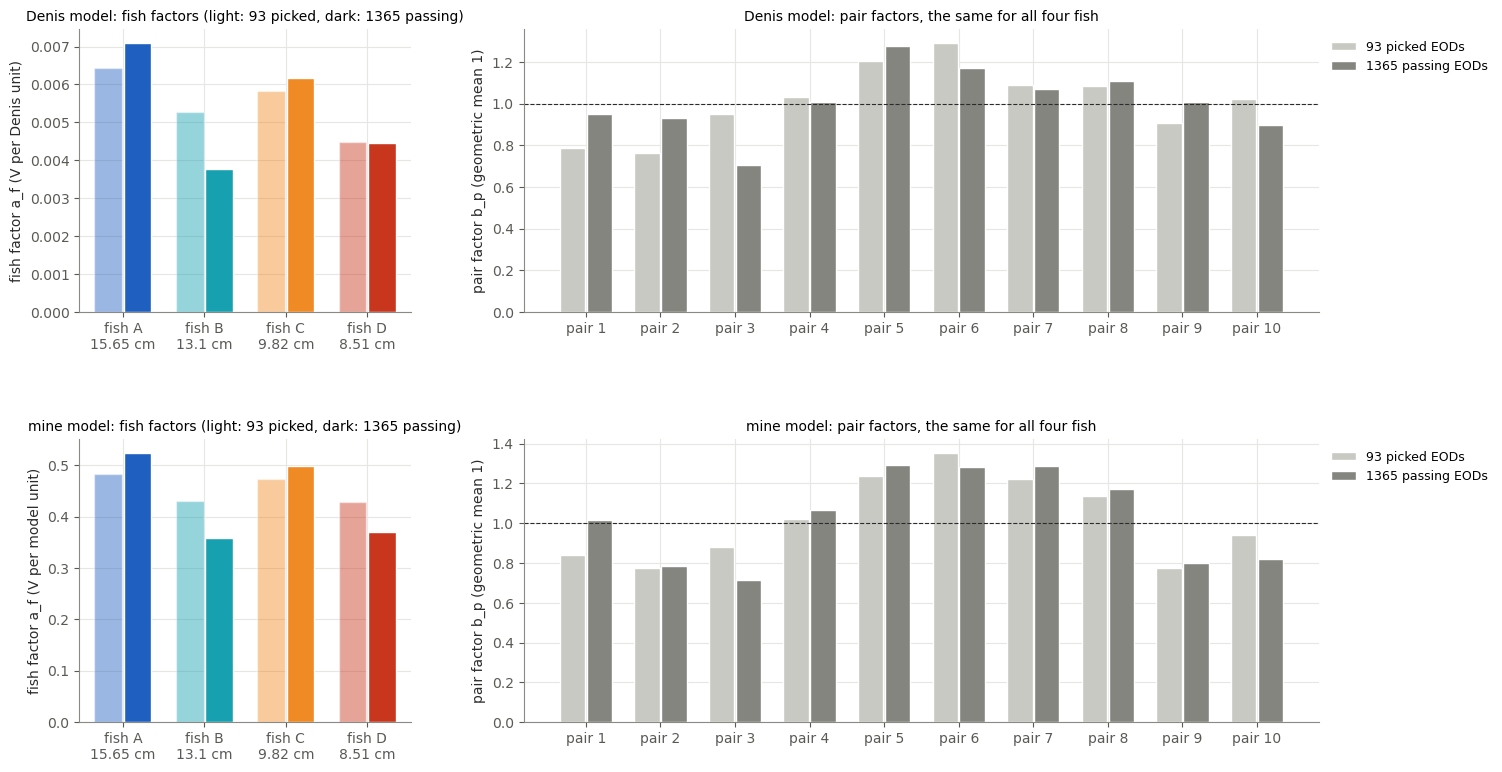

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(16, 9), gridspec_kw=dict(width_ratios=[1, 2.4], hspace=0.45))
for r_, m in enumerate(('Denis', 'mine')):
    ax, bx = axs[r_]
    for k, s in enumerate(SETS):
        a, b = FAC[(s, m)]; off = (k - 0.5) * 0.36
        ax.bar(np.arange(4) + off, a, 0.34, color=[FISH_COL[f] for f in LET], alpha=1 if k else 0.45, edgecolor='white')
        bx.bar(np.arange(10) + off, b, 0.34, color='#85857F' if k else '#C9C9C3', edgecolor='white', label=f'{s} EODs')
    ax.set(xticks=range(4), xticklabels=[f'fish {f}\n{L_CM[f]} cm' for f in LET], ylim=(0, None),
           ylabel=f'fish factor a_f ({"V per Denis unit" if m == "Denis" else "V per model unit"})')
    ax.set_title(f'{m} model: fish factors (light: 93 picked, dark: 1365 passing)', fontsize=10)
    bx.axhline(1, color='#2b2b2b', lw=0.8, ls='--')
    bx.set(xticks=range(10), xticklabels=[f'pair {p}' for p in range(1, 11)], ylim=(0, None), ylabel='pair factor b_p (geometric mean 1)')
    bx.set_title(f'{m} model: pair factors, the same for all four fish', fontsize=10)
    bx.legend(frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(1.0, 1.0))
fig.savefig(f'{OUT}/fish_and_pair_factors.png', dpi=110, bbox_inches='tight'); plt.show()

### Is one pair factor per pair enough for all four fish?

Median of $g / (a_f b_p)$ per fish and pair: 1 (white) means that cell is described by its fish and pair factors; the colour
shows log2 of it. Blank: no ratios.

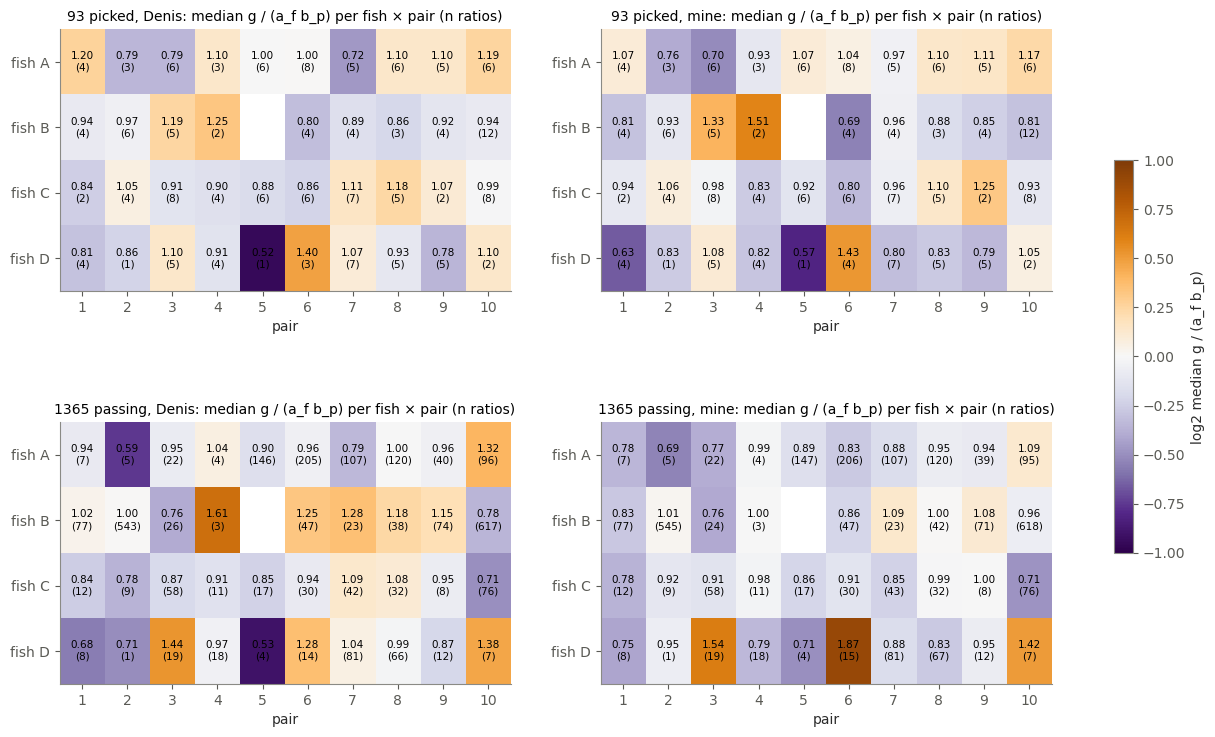

In [4]:
fig, axs = plt.subplots(2, 2, figsize=(16, 8.5), gridspec_kw=dict(hspace=0.5))
for ax, ((s, m), d) in zip(axs.ravel(), DATA.items()):
    a, b = FAC[(s, m)]; g, fi, pi = idx(d)
    res = pd.DataFrame(dict(fish=d.fish, pair=d.pair, r=g / (a[fi] * b[pi])))
    med = res.pivot_table(index='fish', columns='pair', values='r', aggfunc='median').reindex(index=list(LET), columns=range(1, 11))
    n = res.pivot_table(index='fish', columns='pair', values='r', aggfunc='size').reindex(index=list(LET), columns=range(1, 11))
    im = ax.imshow(np.log2(med.to_numpy(float)), cmap='PuOr_r', vmin=-1, vmax=1, aspect='auto')
    for i in range(4):
        for j in range(10):
            if np.isfinite(med.iloc[i, j]): ax.text(j, i, f'{med.iloc[i, j]:.2f}\n({int(n.iloc[i, j])})', ha='center', va='center', fontsize=7.5)
    ax.set(xticks=range(10), xticklabels=range(1, 11), yticks=range(4), yticklabels=[f'fish {f}' for f in LET], xlabel='pair')
    ax.set_title(f'{s}, {m}: median g / (a_f b_p) per fish × pair (n ratios)', fontsize=10); ax.grid(False)
fig.colorbar(im, ax=axs, shrink=0.6, label='log2 median g / (a_f b_p)')
fig.savefig(f'{OUT}/residual_fish_x_pair.png', dpi=110, bbox_inches='tight'); plt.show()

## Do the fish factors scale with fish length?

In [5]:
def length_fits(x, y):
    ok = np.isfinite(y) & (y > 0)
    s, c = np.polyfit(x[ok], y[ok], 1); e, lk = np.polyfit(np.log(x[ok]), np.log(y[ok]), 1)
    return [s, c, e, np.exp(lk)]

def all_fits(d):
    g, fi, pi = idx(d); a, b = fit_ls(g, fi, pi, iters=150)
    ok = np.isfinite(a)
    return length_fits(LF[ok], a[ok]) + length_fits(d.L_cm.to_numpy(), g / b[pi])

rng = np.random.default_rng(0); rows = []; FITS = {}
NAMES = ['slope s (per cm)', 'intercept c', 'exponent e', 'k']
for (s, m), d in DATA.items():
    est = all_fits(d); FITS[(s, m)] = est
    grp = list(d.groupby('eod').indices.values()); B = []
    for _ in range(NBOOT):
        bi = np.concatenate([grp[k] for k in rng.integers(0, len(grp), len(grp))]); db = d.iloc[bi]
        if db.fish.nunique() >= 3: B.append(all_fits(db))
    lo, hi = np.nanpercentile(np.array(B), [2.5, 97.5], axis=0)
    for k in range(8):
        rows.append(dict(set=s, model=m, fit_to='4 fish factors a_f' if k < 4 else 'ratios / pair factor', parameter=NAMES[k % 4],
                         estimate=est[k], ci_low=lo[k], ci_high=hi[k]))
FT = pd.DataFrame(rows); FT.to_csv(f'{OUT}/length_fits.csv', index=False)
show = FT.assign(value=[f'{e:.3g}  [{l:.3g}, {h:.3g}]' for e, l, h in zip(FT.estimate, FT.ci_low, FT.ci_high)])
display(show.pivot_table(index=['model', 'set', 'fit_to'], columns='parameter', values='value', aggfunc='first')[NAMES])

parameter                                              slope s (per cm)  \
model set          fit_to                                                 
Denis 1365 passing 4 fish factors a_f    0.000194  [0.000152, 0.000236]   
                   ratios / pair factor  0.000276  [0.000219, 0.000334]   
      93 picked    4 fish factors a_f    0.000191  [8.49e-05, 0.000286]   
                   ratios / pair factor  0.000195  [8.02e-05, 0.000291]   
mine  1365 passing 4 fish factors a_f         0.0106  [0.00611, 0.0155]   
                   ratios / pair factor       0.0133  [0.00871, 0.0181]   
      93 picked    4 fish factors a_f       0.00408  [-0.00639, 0.0148]   
                   ratios / pair factor     0.00598  [-0.00329, 0.0149]   

parameter                                                 intercept c  \
model set          fit_to                                               
Denis 1365 passing 4 fish factors a_f      0.0031  [0.00257, 0.00363]   
                   ratios / pair factor  0.00139  [0.000616, 0.00214]   
      93 picked    4 fish factors a_f     0.00325  [0.00212, 0.00449]   
                   ratios / pair factor   0.00326  [0.00209, 0.00462]   
mine  1365 passing 4 fish factors a_f             0.312  [0.25, 0.37]   
                   ratios / pair factor         0.247  [0.187, 0.305]   
      93 picked    4 fish factors a_f           0.406  [0.273, 0.537]   
                   ratios / pair factor         0.385  [0.278, 0.496]   

parameter                                             exponent e  \
model set          fit_to                                          
Denis 1365 passing 4 fish factors a_f      0.327  [0.237, 0.416]   
                   ratios / pair factor    0.441  [0.325, 0.555]   
      93 picked    4 fish factors a_f      0.416  [0.184, 0.627]   
                   ratios / pair factor    0.417  [0.164, 0.635]   
mine  1365 passing 4 fish factors a_f        0.261  [0.137, 0.4]   
                   ratios / pair factor    0.311  [0.207, 0.419]   
      93 picked    4 fish factors a_f     0.102  [-0.179, 0.411]   
                   ratios / pair factor  0.181  [-0.0656, 0.417]   

parameter                                                          k  
model set          fit_to                                             
Denis 1365 passing 4 fish factors a_f    0.00235  [0.00187, 0.00294]  
                   ratios / pair factor  0.00148  [0.00111, 0.00199]  
      93 picked    4 fish factors a_f    0.00198  [0.00116, 0.00347]  
                   ratios / pair factor  0.00189  [0.00111, 0.00349]  
mine  1365 passing 4 fish factors a_f          0.228  [0.162, 0.313]  
                   ratios / pair factor        0.179  [0.135, 0.231]  
      93 picked    4 fish factors a_f            0.354  [0.165, 0.7]  
                   ratios / pair factor        0.277  [0.156, 0.502]

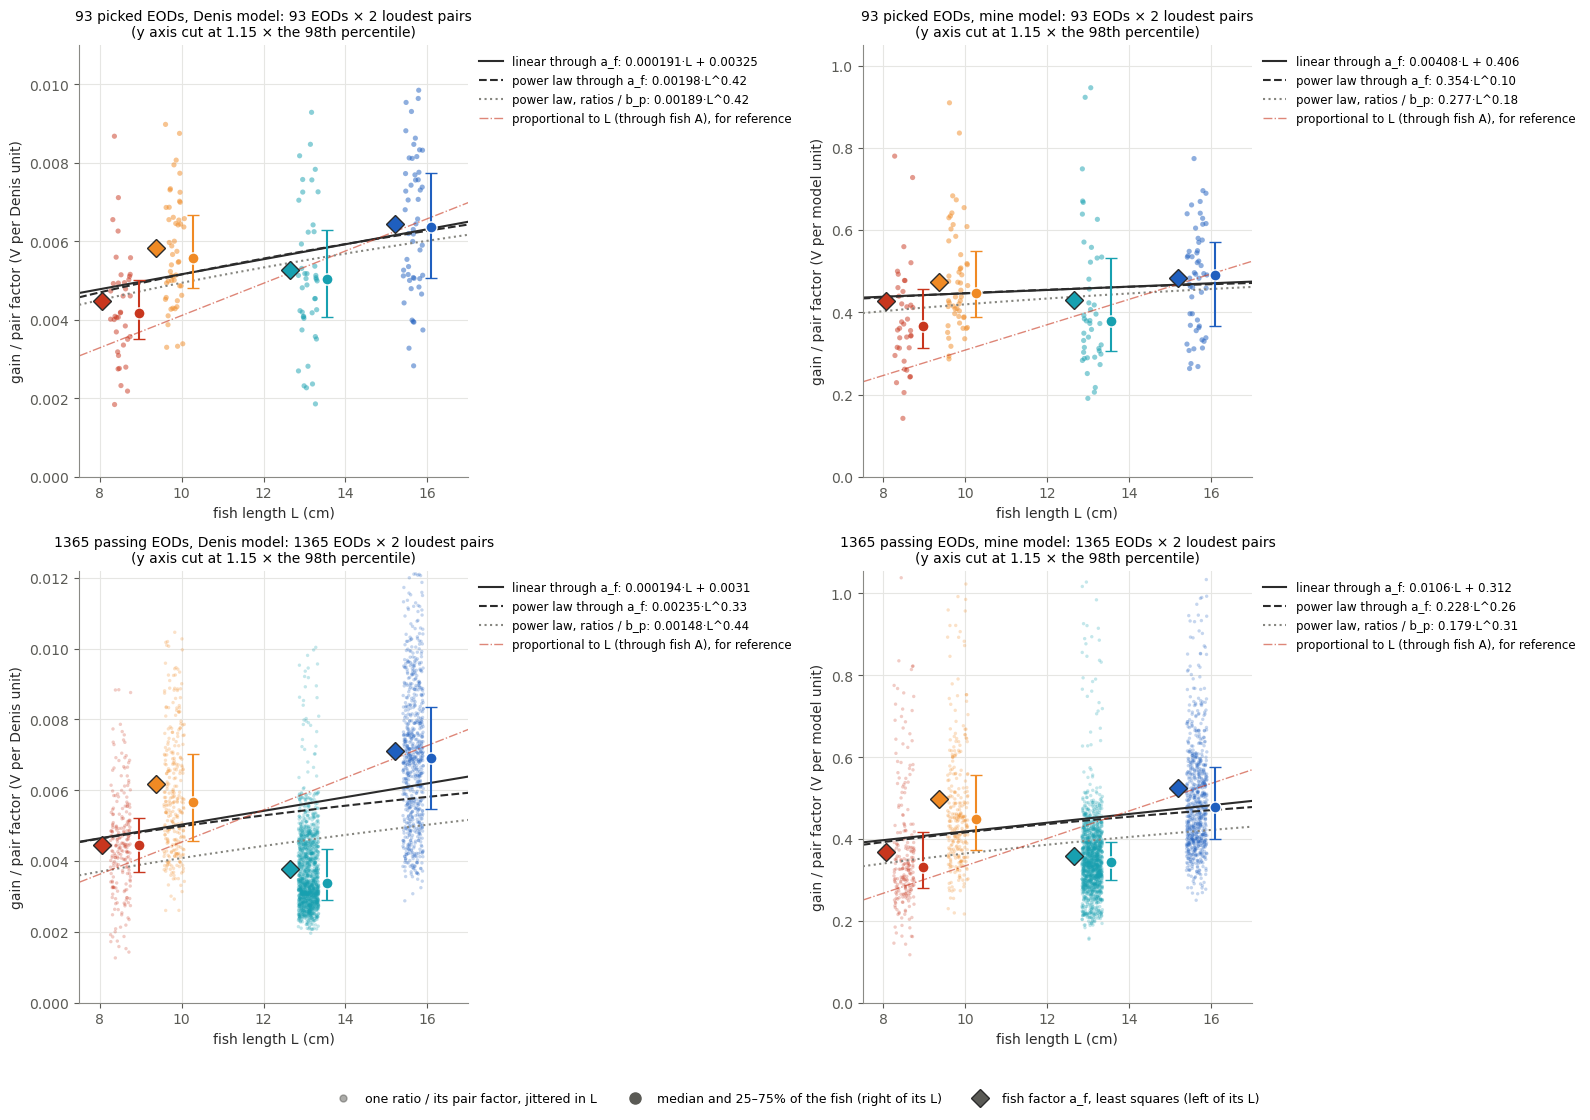

In [6]:
fig, axs = plt.subplots(2, 2, figsize=(16, 11))
xs = np.linspace(7.5, 17, 100); jit = np.random.default_rng(1)
for ax, ((s, m), d) in zip(axs.ravel(), DATA.items()):
    s_f, c_f, e_f, k_f, s_r, c_r, e_r, k_r = FITS[(s, m)]; a, b = FAC[(s, m)]; g, fi, pi = idx(d); y = g / b[pi]
    for j, f in enumerate(LET):
        k = fi == j
        ax.scatter(LF[j] + jit.uniform(-0.25, 0.25, k.sum()), y[k], s=6 if len(d) > 1000 else 14, alpha=0.25 if len(d) > 1000 else 0.5,
                   color=FISH_COL[f], edgecolor='none', zorder=2)
        q = np.percentile(y[k], [25, 50, 75])
        ax.errorbar(LF[j] + 0.45, q[1], yerr=[[q[1] - q[0]], [q[2] - q[1]]], fmt='o', ms=8, color=FISH_COL[f], mec='white', capsize=4, zorder=4)
        ax.plot(LF[j] - 0.45, a[j], 'D', ms=9, color=FISH_COL[f], mec='#2b2b2b', zorder=4)
    ax.plot(xs, s_f * xs + c_f, color='#2b2b2b', lw=1.5, label=f'linear through a_f: {s_f:.3g}·L {"+" if c_f >= 0 else "−"} {abs(c_f):.3g}')
    ax.plot(xs, k_f * xs ** e_f, color='#2b2b2b', lw=1.5, ls='--', label=f'power law through a_f: {k_f:.3g}·L^{e_f:.2f}')
    ax.plot(xs, k_r * xs ** e_r, color='#85857F', lw=1.5, ls=':', label=f'power law, ratios / b_p: {k_r:.3g}·L^{e_r:.2f}')
    ax.plot(xs, a[np.argmax(LF)] * xs / LF.max(), color='#C8361E', lw=1, ls='-.', alpha=0.6, label='proportional to L (through fish A), for reference')
    ax.set(xlim=(7.5, 17), ylim=(0, np.percentile(y, 98) * 1.15), xlabel='fish length L (cm)',
           ylabel=f'gain / pair factor ({"V per Denis unit" if m == "Denis" else "V per model unit"})')
    ax.set_title(f'{s} EODs, {m} model: {d.eod.nunique()} EODs × {NTOP} loudest pairs\n(y axis cut at 1.15 × the 98th percentile)', fontsize=10)
    ax.legend(frameon=False, fontsize=8.5, loc='upper left', bbox_to_anchor=(1.0, 1.0))
h = [Line2D([], [], marker='o', ls='', ms=5, color='#5a5a55', alpha=0.5, label='one ratio / its pair factor, jittered in L'),
     Line2D([], [], marker='o', ls='', ms=8, color='#5a5a55', label='median and 25–75% of the fish (right of its L)'),
     Line2D([], [], marker='D', ls='', ms=9, color='#5a5a55', mec='#2b2b2b', label='fish factor a_f, least squares (left of its L)')]
fig.legend(handles=h, frameon=False, loc='lower center', ncol=3, fontsize=9, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(f'{OUT}/fish_factor_vs_length.png', dpi=110, bbox_inches='tight'); plt.show()

## Per video (1365 passing EODs)

The same least squares (4 fish factors × 10 pair factors, pair factors shared by the fish) fitted on each video's EODs alone.
A video only fixes the products $a_f b_p$, so its factors are put on the scale of the all-video fit: b is rescaled so its
geometric mean over the pairs that video has equals that of the all-video b over the same pairs (a scaled the other way; no
prediction changes). A factor is drawn only with ≥ 10 ratios in that video (small numbers under the bars: ratios per video).
Black tick: the all-video fit. 11_12_57 contributes only 4 passing EODs (all fish D: A, B and C are never ≥ 10 cm from the
others in that video's good-mask frames), too few for any factor, so it has no bars.

Denis model, 1365 passing: factors per video (n ratios)


video,05_52_55,06_52_55,15_16_23,19_16_25,all five
factor,,,,,
fish A,0.00658 (328),0.00716 (334),0.0103 (82),– (8),0.00711 (752)
fish B,0.00379 (22),0.00292 (188),0.00366 (1114),0.00565 (124),0.00378 (1448)
fish C,0.00564 (217),0.00668 (36),0.0102 (38),– (4),0.00617 (295)
fish D,0.0045 (91),0.00409 (93),– (0),0.00347 (38),0.00445 (230)
pair 1,0.799 (29),– (6),1.17 (68),– (1),0.949 (104)
pair 2,0.748 (16),1.08 (66),0.996 (473),– (3),0.932 (558)
pair 3,0.695 (77),0.729 (16),– (6),1.22 (26),0.707 (125)
pair 4,1.02 (11),– (1),– (1),1.3 (23),1.01 (36)
pair 5,1.49 (89),1.26 (47),0.655 (29),– (2),1.27 (167)


mine model, 1365 passing: factors per video (n ratios)


video,05_52_55,06_52_55,15_16_23,19_16_25,all five
factor,,,,,
fish A,0.473 (328),0.535 (334),0.649 (82),– (8),0.524 (752)
fish B,0.351 (22),0.257 (188),0.342 (1116),0.424 (124),0.358 (1450)
fish C,0.493 (218),0.474 (36),0.741 (38),– (4),0.499 (296)
fish D,0.408 (92),0.291 (94),– (0),0.279 (38),0.37 (232)
pair 1,0.834 (29),– (6),1.22 (68),– (1),1.02 (104)
pair 2,0.728 (16),0.861 (66),0.853 (475),– (3),0.787 (560)
pair 3,0.668 (77),0.802 (16),– (4),1.23 (26),0.713 (123)
pair 4,1.1 (11),– (1),– (1),1.36 (23),1.06 (36)
pair 5,1.48 (89),1.38 (47),0.84 (30),– (2),1.29 (168)


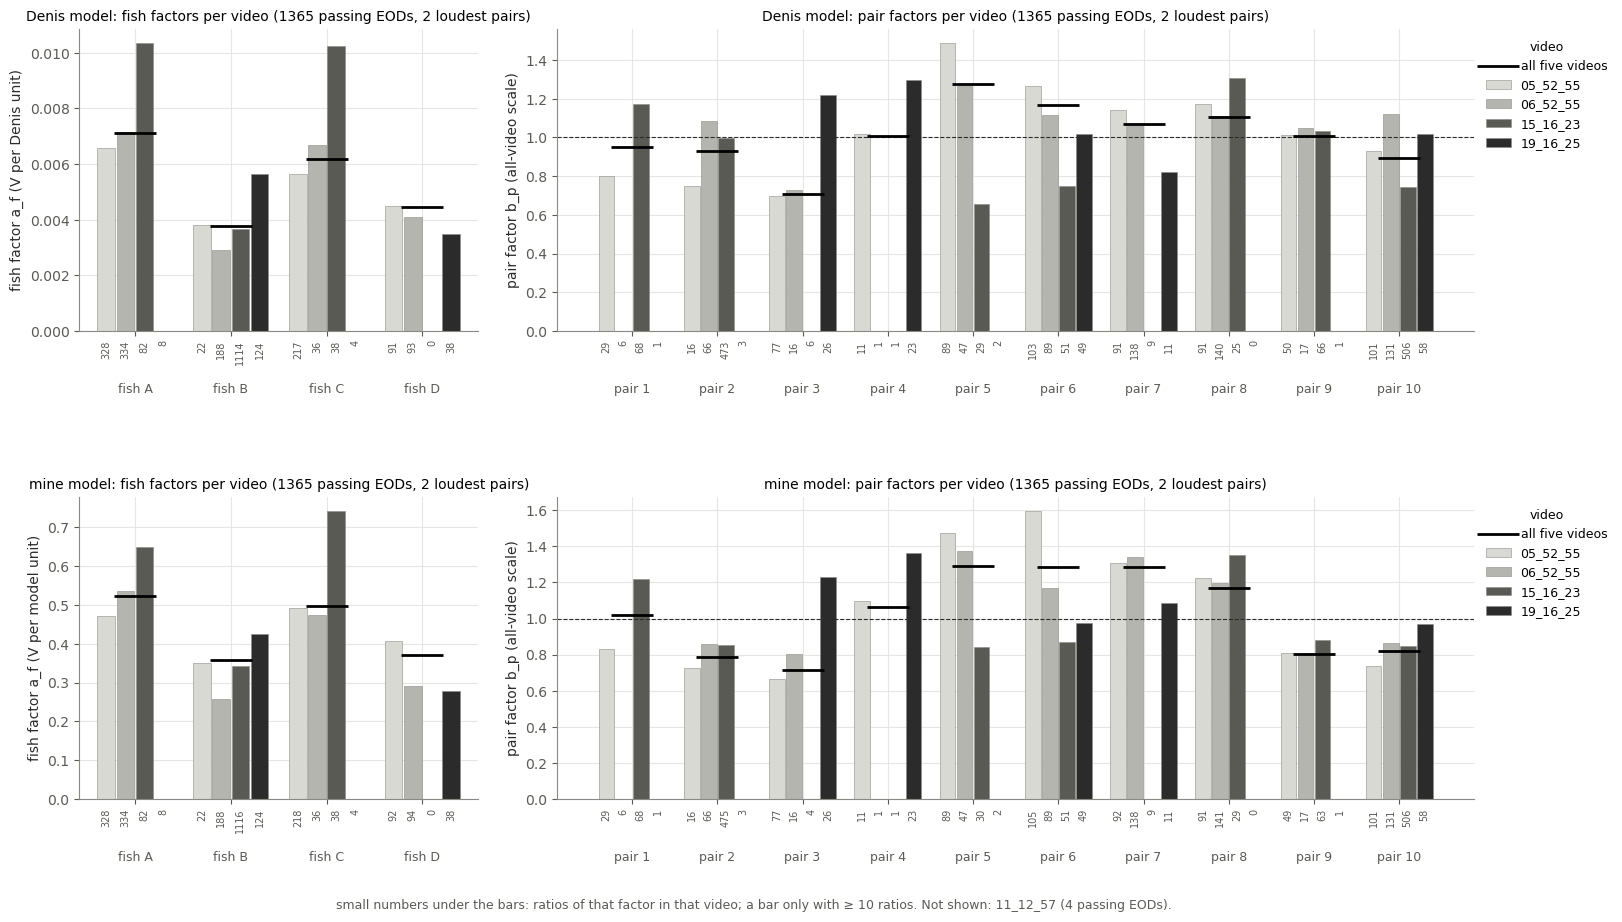

In [7]:
S = '1365 passing'; RECS = sorted(DATA[(S, 'mine')].video.unique()); MIN_N = 10
VCOL = dict(zip(RECS, ['#D9D9D4', '#B5B5AF', '#8A8A85', '#5A5A55', '#2B2B2B']))
rows = []
for m in ('Denis', 'mine'):
    d = DATA[(S, m)]; a_all, b_all = FAC[(S, m)]
    for t in RECS:
        g, fi, pi = idx(d[d.video == t]); a, b = fit_ls(g, fi, pi)
        seen = np.isfinite(b); c = np.exp(np.mean(np.log(b[seen])) - np.mean(np.log(b_all[seen]))); a, b = a * c, b / c
        nf, npr = np.bincount(fi, minlength=4), np.bincount(pi, minlength=10)
        rows += [dict(model=m, video=t, factor=f'fish {f}', value=a[j], n=int(nf[j])) for j, f in enumerate(LET)]
        rows += [dict(model=m, video=t, factor=f'pair {p + 1}', value=b[p], n=int(npr[p])) for p in range(10)]
    rows += [dict(model=m, video='all five', factor=nm, value=v, n=int(n)) for nm, v, n in
             zip([f'fish {f}' for f in LET] + [f'pair {p}' for p in range(1, 11)], np.r_[a_all, b_all],
                 np.r_[np.bincount(d.fish.map(LET.index), minlength=4), np.bincount(d.pair - 1, minlength=10)])]
PV = pd.DataFrame(rows); PV.loc[PV.n < MIN_N, 'value'] = np.nan
PV.to_csv(f'{OUT}/factors_per_video_1365.csv', index=False)
for m in ('Denis', 'mine'):
    t_ = PV[PV.model == m].pivot_table(index='factor', columns='video', values='value', sort=False)
    n_ = PV[PV.model == m].pivot_table(index='factor', columns='video', values='n', sort=False)
    show = t_.copy().astype(object)
    for c in t_.columns: show[c] = [f'{v:.3g} ({int(n)})' if np.isfinite(v) else f'– ({int(n)})' for v, n in zip(t_[c], n_[c])]
    print(f'{m} model, 1365 passing: factors per video (n ratios)'); display(show)

fig, axs = plt.subplots(2, 2, figsize=(18, 10), gridspec_kw=dict(width_ratios=[1, 2.3], hspace=0.55, wspace=0.12))
for r_, m in enumerate(('Denis', 'mine')):
    P_ = PV[PV.model == m]
    for ax, names, ylab in ((axs[r_, 0], [f'fish {f}' for f in LET], f'fish factor a_f ({"V per Denis unit" if m == "Denis" else "V per model unit"})'),
                            (axs[r_, 1], [f'pair {p}' for p in range(1, 11)], 'pair factor b_p (all-video scale)')):
        x = np.arange(len(names))
        PLOT = [t for t in RECS if P_[(P_.video == t)].value.notna().any()]; w = 0.8 / len(PLOT)
        for k, t in enumerate(PLOT):
            v = P_[P_.video == t].set_index('factor').loc[names]; xx = x + (k - (len(PLOT) - 1) / 2) * w
            ax.bar(xx, v.value, w * 0.92, color=VCOL[t], edgecolor='#8a8a85', lw=0.4, label=t)
            for xi, n in zip(xx, v.n):
                ax.text(xi, -0.03, str(int(n)), transform=ax.get_xaxis_transform(), rotation=90, ha='center', va='top', fontsize=7, color='#5a5a55')
        allv = P_[P_.video == 'all five'].set_index('factor').loc[names].value
        ax.scatter(x, allv, marker='_', s=900, color='#000000', lw=2, zorder=5, label='all five videos')
        ax.set_xticks(x); ax.set_xticklabels(names, fontsize=9); ax.tick_params(axis='x', pad=34)
        if names[0].startswith('pair'): ax.axhline(1, color='#2b2b2b', lw=0.8, ls='--')
        ax.set(ylabel=ylab, ylim=(0, None))
        ax.set_title(f'{m} model: {"fish" if names[0].startswith("fish") else "pair"} factors per video (1365 passing EODs, 2 loudest pairs)', fontsize=10)
    axs[r_, 1].legend(frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(1.0, 1.0), title='video', title_fontsize=9)
gone = [t for t in RECS if t not in PLOT]
fig.text(0.5, 0.0, f'small numbers under the bars: ratios of that factor in that video; a bar only with ≥ {MIN_N} ratios. '
         + (f'Not shown: {", ".join(gone)} ({", ".join(str(SETS[S][SETS[S].video == t].shape[0]) for t in gone)} passing EODs).' if gone else ''),
         ha='center', fontsize=9, color='#5a5a55')
fig.savefig(f'{OUT}/factors_per_video_1365.png', dpi=110, bbox_inches='tight'); plt.show()

## How much of the variability of the ratios do fish and pair factors explain? (1365 passing EODs × 2 pairs)

Explained variance $R^2 = 1 - \sum (g - \hat g)^2 / \sum (g - \bar g)^2$ of the ratios g, within each video and over all
videos, for these predictions $\hat g$ (each fitted by least squares on the ratios it is scored on):
- **fish only**: one gain per fish, $\hat g = a_f$;
- **pair only**: one gain per pair, $\hat g = b_p$;
- **fish × pair factors**: $\hat g = a_f b_p$ (4 + 10 factors, pair factors shared by the fish): in a video, fitted on that video;
  over all videos, one fit on all five;
- **fish × pair factors, per video** (all videos only): $a_f b_p$ refitted in each video, i.e. 5 sets of factors;
- **ceiling: one gain per fish × pair** ($\hat g$ = mean ratio of that fish on that pair; over all videos also per fish × pair ×
  video): the most any per-fish and per-pair gain can explain, even with interactions; the rest is EOD-to-EOD variability.

Left: on the ratios (what the fit minimises). Right: the same on log ratios (each fit redone in log), where a factor of 2 up
or down counts the same. 11_12_57 is left out of the per-video groups (8 ratios, all fish D) but is in "all videos".

Denis model: R² (%) of the ratios / of the log ratios


scale              ratios                                \
what            fish only pair only fish × pair factors   
group      n                                              
05_52_55   658       19.5      28.8                34.6   
06_52_55   651       55.7      28.2                57.6   
15_16_23   1234      57.7      45.9                70.5   
19_16_25   174       26.3      15.8                36.5   
all videos 2725      47.3      37.5                52.6   

scale                                                        \
what            ceiling: one gain per fish × pair (× video)   
group      n                                                  
05_52_55   658                                         40.7   
06_52_55   651                                         60.8   
15_16_23   1234                                        75.4   
19_16_25   174                                         38.5   
all videos 2725                                        64.0   

scale                                           \
what            fish × pair factors, per video   
group      n                                     
05_52_55   658                             NaN   
06_52_55   651                             NaN   
15_16_23   1234                            NaN   
19_16_25   174                             NaN   
all videos 2725                           60.2   

scale                                                  log ratios            \
what            ceiling, fish × pair only (all videos)  fish only pair only   
group      n                                                                  
05_52_55   658                                     NaN       28.5      37.3   
06_52_55   651                                     NaN       68.9      39.1   
15_16_23   1234                                    NaN       46.5      49.6   
19_16_25   174                                     NaN       31.8      22.2   
all videos 2725                                   57.7       53.9      44.3   

scale                                \
what            fish × pair factors   
group      n                          
05_52_55   658                 46.8   
06_52_55   651                 72.1   
15_16_23   1234                71.6   
19_16_25   174                 43.1   
all videos 2725                62.5   

scale                                                        \
what            ceiling: one gain per fish × pair (× video)   
group      n                                                  
05_52_55   658                                         55.8   
06_52_55   651                                         77.7   
15_16_23   1234                                        73.8   
19_16_25   174                                         44.6   
all videos 2725                                        77.2   

scale                                           \
what            fish × pair factors, per video   
group      n                                     
05_52_55   658                             NaN   
06_52_55   651                             NaN   
15_16_23   1234                            NaN   
19_16_25   174                             NaN   
all videos 2725                           73.3   

scale                                                   
what            ceiling, fish × pair only (all videos)  
group      n                                            
05_52_55   658                                     NaN  
06_52_55   651                                     NaN  
15_16_23   1234                                    NaN  
19_16_25   174                                     NaN  
all videos 2725                                   68.3

mine model: R² (%) of the ratios / of the log ratios


scale              ratios                                \
what            fish only pair only fish × pair factors   
group      n                                              
05_52_55   660        6.6      25.7                26.7   
06_52_55   652       46.1      33.8                52.8   
15_16_23   1236      39.2      34.1                48.4   
19_16_25   174       11.1       8.7                19.4   
all videos 2730      30.3      33.9                40.3   

scale                                                        \
what            ceiling: one gain per fish × pair (× video)   
group      n                                                  
05_52_55   660                                         30.2   
06_52_55   652                                         54.5   
15_16_23   1236                                        50.4   
19_16_25   174                                         26.3   
all videos 2730                                        48.7   

scale                                           \
what            fish × pair factors, per video   
group      n                                     
05_52_55   660                             NaN   
06_52_55   652                             NaN   
15_16_23   1236                            NaN   
19_16_25   174                             NaN   
all videos 2730                           46.4   

scale                                                  log ratios            \
what            ceiling, fish × pair only (all videos)  fish only pair only   
group      n                                                                  
05_52_55   660                                     NaN       14.3      44.4   
06_52_55   652                                     NaN       71.0      51.9   
15_16_23   1236                                    NaN       43.5      38.3   
19_16_25   174                                     NaN       13.4      14.2   
all videos 2730                                   43.3       44.1      47.9   

scale                                \
what            fish × pair factors   
group      n                          
05_52_55   660                 47.8   
06_52_55   652                 78.4   
15_16_23   1236                52.6   
19_16_25   174                 24.2   
all videos 2730                57.0   

scale                                                        \
what            ceiling: one gain per fish × pair (× video)   
group      n                                                  
05_52_55   660                                         54.4   
06_52_55   652                                         81.6   
15_16_23   1236                                        54.4   
19_16_25   174                                         29.4   
all videos 2730                                        70.2   

scale                                           \
what            fish × pair factors, per video   
group      n                                     
05_52_55   660                             NaN   
06_52_55   652                             NaN   
15_16_23   1236                            NaN   
19_16_25   174                             NaN   
all videos 2730                           66.9   

scale                                                   
what            ceiling, fish × pair only (all videos)  
group      n                                            
05_52_55   660                                     NaN  
06_52_55   652                                     NaN  
15_16_23   1236                                    NaN  
19_16_25   174                                     NaN  
all videos 2730                                   60.5

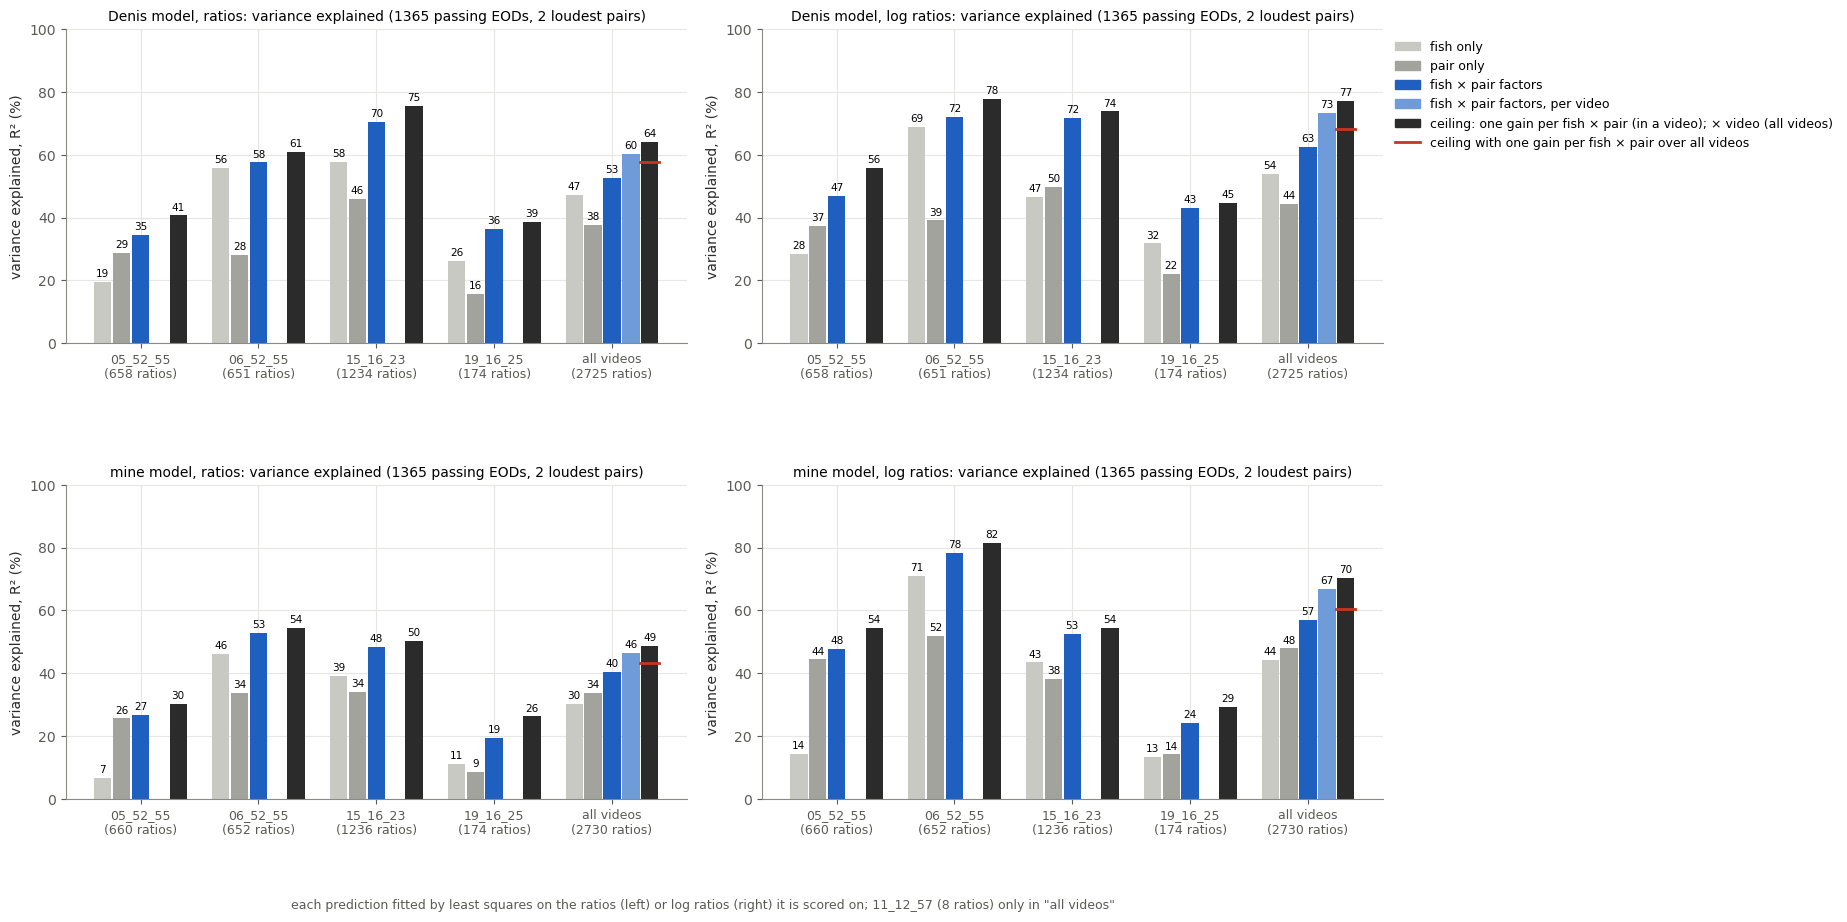

In [8]:
def r2(y, yh): return 1 - ((y - yh) ** 2).sum() / ((y - y.mean()) ** 2).sum()
def group_mean(y, *keys):
    k = pd.Series(list(zip(*keys))); return pd.Series(y).groupby(k).transform('mean').to_numpy()
def fit_pred(y, fi, pi, log):
    if log: a, b = fit_log(np.exp(y), fi, pi); return np.log(a[fi] * b[pi])
    a, b = fit_ls(y, fi, pi); return a[fi] * b[pi]

BARS = ['fish only', 'pair only', 'fish × pair factors', 'fish × pair factors, per video', 'ceiling: one gain per fish × pair (× video)']
BCOL = dict(zip(BARS, ['#C9C9C3', '#A3A39D', '#1F5FBF', '#6F9BD8', '#2b2b2b']))
rows = []
for m in ('Denis', 'mine'):
    d = DATA[(S, m)]
    for log in (False, True):
        for grp in RECS + ['all videos']:
            dd = d if grp == 'all videos' else d[d.video == grp]
            if len(dd) < 30: continue
            g, fi, pi = idx(dd); y = np.log(g) if log else g; v = dd.video.to_numpy()
            res = {'fish only': r2(y, group_mean(y, fi)), 'pair only': r2(y, group_mean(y, pi)),
                   'fish × pair factors': r2(y, fit_pred(y, fi, pi, log))}
            if grp == 'all videos':
                yh = np.empty_like(y)
                for t in np.unique(v):
                    k = v == t; yh[k] = fit_pred(y[k], fi[k], pi[k], log)
                res['fish × pair factors, per video'] = r2(y, yh)
                res['ceiling: one gain per fish × pair (× video)'] = r2(y, group_mean(y, fi, pi, v))
                res['ceiling, fish × pair only (all videos)'] = r2(y, group_mean(y, fi, pi))
            else:
                res['ceiling: one gain per fish × pair (× video)'] = r2(y, group_mean(y, fi, pi))
            rows += [dict(model=m, scale='log ratios' if log else 'ratios', group=grp, n=len(dd), what=k_, R2=v_) for k_, v_ in res.items()]
VE = pd.DataFrame(rows); VE.to_csv(f'{OUT}/variance_explained_1365.csv', index=False)
for m in ('Denis', 'mine'):
    print(f'{m} model: R² (%) of the ratios / of the log ratios')
    t_ = VE[VE.model == m].pivot_table(index=['group', 'n'], columns=['scale', 'what'], values='R2', sort=False) * 100
    display(t_.round(1))

GROUPS = [g for g in RECS + ['all videos'] if (VE.group == g).any()]
fig, axs = plt.subplots(2, 2, figsize=(17, 10), gridspec_kw=dict(hspace=0.45, wspace=0.12))
for r_, m in enumerate(('Denis', 'mine')):
    for c_, sc in enumerate(('ratios', 'log ratios')):
        ax = axs[r_, c_]; V_ = VE[(VE.model == m) & (VE.scale == sc)]
        w = 0.8 / len(BARS)
        for k, b_ in enumerate(BARS):
            vals = [V_[(V_.group == g) & (V_.what == b_)].R2.max() if ((V_.group == g) & (V_.what == b_)).any() else np.nan for g in GROUPS]
            xx = np.arange(len(GROUPS)) + (k - (len(BARS) - 1) / 2) * w
            ax.bar(xx, np.array(vals) * 100, w * 0.92, color=BCOL[b_], label=b_)
            for xi, v_ in zip(xx, vals):
                if np.isfinite(v_): ax.text(xi, max(v_, 0) * 100 + 1, f'{v_ * 100:.0f}', ha='center', va='bottom', fontsize=7.5)
        cg = V_[(V_.group == 'all videos') & (V_.what == 'ceiling, fish × pair only (all videos)')].R2.iloc[0] * 100
        ax.plot([len(GROUPS) - 1 + 0.4 - w, len(GROUPS) - 1 + 0.4], [cg, cg], color='#C8361E', lw=2)
        ns = V_.groupby('group').n.first()
        ax.set_xticks(range(len(GROUPS))); ax.set_xticklabels([f'{g}\n({ns[g]} ratios)' for g in GROUPS], fontsize=9)
        ax.set(ylim=(0, 100), ylabel='variance explained, R² (%)')
        ax.set_title(f'{m} model, {sc}: variance explained (1365 passing EODs, 2 loudest pairs)', fontsize=10)
axs[0, 1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BCOL[b_]) for b_ in BARS] +
                 [Line2D([], [], color='#C8361E', lw=2)], labels=BARS[:-1] + ['ceiling: one gain per fish × pair (in a video); × video (all videos)',
                 'ceiling with one gain per fish × pair over all videos'], frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(1.0, 1.0))
fig.text(0.5, 0.0, 'each prediction fitted by least squares on the ratios (left) or log ratios (right) it is scored on; 11_12_57 (8 ratios) only in "all videos"',
         ha='center', fontsize=9, color='#5a5a55')
fig.savefig(f'{OUT}/variance_explained_1365.png', dpi=110, bbox_inches='tight'); plt.show()